# 02 · Customer segmentation (dev and val windows only)

> **Illustrative scenario.** The business framing is invented. The data is real (a UK online gift retailer, 2009-2011, with many wholesale buyers) and contains **no marketing contact data**. "Repeat-purchase rate" means ordering again within 90 days, not response to marketing.

**Design.** Segments are fitted on the **dev** window (cutoff 2011-03-15) and frozen: winsorisation caps, transforms, standardisation, k, centroids and each segment's repeat-purchase rate all come from dev. Feature set A (RFM core) or B (behavioural) is chosen on the **val** window. The **test** window is not built or read in this notebook; it is evaluated later, after everything is frozen (docs/METHODOLOGY.md section 6 says how often it was scored).

Rules from the analysis plan: k in 3-8; every segment must hold at least 5% of customers; stability is the 5th percentile of the adjusted Rand index (ARI) over 200 bootstrap refits; k is chosen strictly by the ARI 5th percentile (owner decision); silhouette and then the smaller k only break exact ties.

In [1]:
import copy
import json
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score

from segmentation_propensity.data import clean_lines, connect, load_raw
from segmentation_propensity.features import build_snapshot
from segmentation_propensity.segmentation import (
    Preprocessor, evaluate_k_grid, fit_segment_model, save_selection, segment_profiles, select_segmentation,
)
from segmentation_propensity.utils import load_config, resolve, set_seed

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3})
cfg = load_config(Path("..") / "config.yaml")
set_seed(cfg["project"]["seed"])
FIG = resolve(cfg, "figures_dir")

raw = load_raw(cfg)
con = connect(cfg)
clean_lines(con, raw, cfg)
snaps = {name: build_snapshot(con, cfg, cfg["windows"]["snapshots"][name]["cutoff"]) for name in ["dev", "val"]}
for name, df in snaps.items():
    print(f"{name}: {len(df):,} customers, {df.y.sum():,} repeat buyers ({df.y.mean():.3f})")
print("Windows built in this notebook:", list(snaps))

dev: 3,856 customers, 1,539 repeat buyers (0.399)
val: 3,905 customers, 1,503 repeat buyers (0.385)
Windows built in this notebook: ['dev', 'val']


## 1. Preprocessing fitted on dev
Caps are the dev 99.5th percentile. `log1p` applies to skewed count and value features only (not recency or tenure, owner decision).

In [2]:
sets = cfg["features"]["segmentation_sets"]
pre_rows = []
for set_name, feats in sets.items():
    pre = Preprocessor.fit(snaps["dev"], feats, cfg)
    for f in feats:
        pre_rows.append({"feature_set": set_name, "feature": f, "dev_cap_p99_5": round(pre.caps[f], 3), "log1p": f in pre.log1p})
pd.DataFrame(pre_rows).pivot_table(index="feature", columns="feature_set", values="log1p", aggfunc="first")

feature_set,A_rfm_core,B_behavioural_extended,C_no_recency_sensitivity
feature,,,
avg_order_value_gbp,NaN,True,True
frequency_invoices,True,True,True
median_units_per_line,NaN,True,True
monetary_net_gbp,True,True,True
n_distinct_products,NaN,True,True
recency_days,False,False,NaN
return_rate_value,NaN,False,False


## 2. Choosing k for each feature set (dev)

In [3]:
result = select_segmentation(snaps, cfg)
grid_all = pd.concat(result["grids"].values(), ignore_index=True)
print("Chosen k per set (None = no k meets the 5% size rule):", result["chosen_k"])
print("Ineligible sets:", result["ineligible_sets"])
grid_all.round(3)

Chosen k per set (None = no k meets the 5% size rule): {'A_rfm_core': 3, 'B_behavioural_extended': 3, 'C_no_recency_sensitivity': None}
Ineligible sets: ['C_no_recency_sensitivity']


,feature_set,k,silhouette,ari_median,ari_p05,min_segment_share,size_ok
0,A_rfm_core,3,0.321,0.927,0.882,0.223,True
1,A_rfm_core,4,0.335,0.946,0.348,0.189,True
2,A_rfm_core,5,0.310,0.889,0.673,0.097,True
3,A_rfm_core,6,0.326,0.931,0.865,0.080,True
4,A_rfm_core,7,0.316,0.774,0.612,0.062,True
5,A_rfm_core,8,0.319,0.838,0.607,0.023,False
6,B_behavioural_extended,3,0.206,0.376,0.329,0.214,True
7,B_behavioural_extended,4,0.203,0.848,0.357,0.024,False
8,B_behavioural_extended,5,0.199,0.880,0.786,0.018,False
9,B_behavioural_extended,6,0.201,0.657,0.412,0.018,False


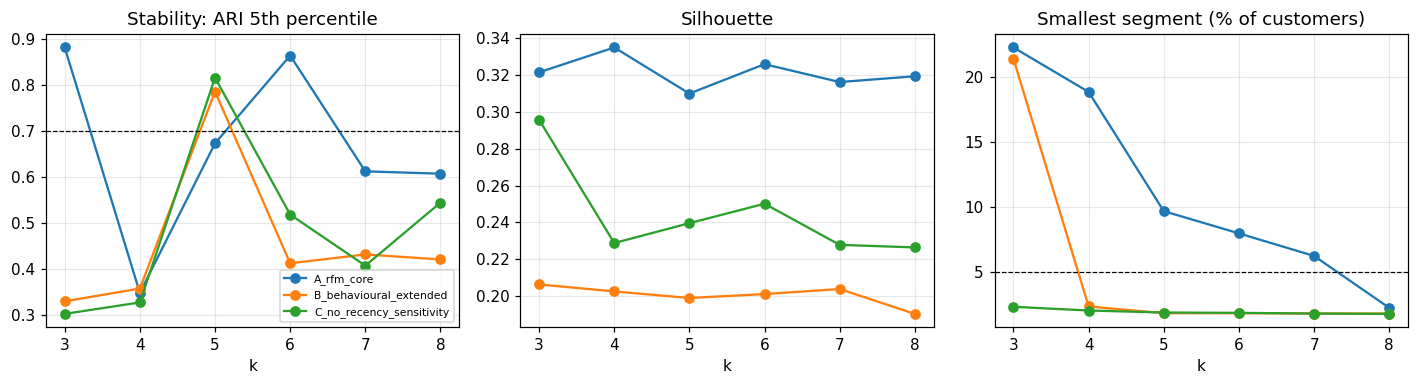

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for name, g in result["grids"].items():
    axes[0].plot(g.k, g.ari_p05, marker="o", label=name)
    axes[1].plot(g.k, g.silhouette, marker="o", label=name)
    axes[2].plot(g.k, 100 * g.min_segment_share, marker="o", label=name)
axes[0].axhline(cfg["segmentation"]["stability_min"], color="k", ls="--", lw=0.8)
axes[0].set(title="Stability: ARI 5th percentile", xlabel="k")
axes[1].set(title="Silhouette", xlabel="k")
axes[2].axhline(100 * cfg["segmentation"]["min_segment_share"], color="k", ls="--", lw=0.8)
axes[2].set(title="Smallest segment (% of customers)", xlabel="k")
axes[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "seg_k_selection.png")

## 3. Why set B fails the size rule above k=3, and set C at every k
Both sets include `return_rate_value`. Most customers return nothing, and a small group returns a large share of what they buy. Standardised, that group sits far from everyone else and k-means gives it its own tiny segment.

In [5]:
dev = snaps["dev"]
rr = dev.return_rate_value
print(f"Customers with no returns: {100 * (rr == 0).mean():.1f}% | 99.5th percentile return rate: {rr.quantile(0.995):.3f}")
B = sets["B_behavioural_extended"]
probe = fit_segment_model(dev, "B_behavioural_extended", 4, cfg)
lab = probe.predict(dev)
sizes = pd.Series(lab).value_counts().sort_index()
smallest = int(sizes.idxmin())
z = pd.Series(probe.centroids[smallest], index=B).round(2)
print(f"Set B, k=4: smallest segment has {sizes.min()} customers ({100 * sizes.min() / len(dev):.1f}%). Its centroid in standard units:")
z

Customers with no returns: 64.9% | 99.5th percentile return rate: 0.440
Set B, k=4: smallest segment has 91 customers (2.4%). Its centroid in standard units:


recency_days             0.16
frequency_invoices      -0.22
monetary_net_gbp        -1.17
avg_order_value_gbp     -0.16
median_units_per_line    0.35
n_distinct_products     -0.77
return_rate_value        5.20
dtype: float64

### Diagnostic only (dev window, not used for selection)
Two variants of set B for the owner's decision: without `return_rate_value`, and with it replaced by a yes/no `has_returns` flag. Only dev-window grid metrics are shown, so the val window is not used again.

In [6]:
dcfg = copy.deepcopy(cfg)
dev_diag = dev.assign(has_returns=(dev.return_rate_value > 0).astype(int))
dcfg["features"]["segmentation_sets"] = {
    "B_without_return_rate": [f for f in B if f != "return_rate_value"],
    "B_with_has_returns_flag": [f if f != "return_rate_value" else "has_returns" for f in B],
}
diag = pd.concat([evaluate_k_grid(dev_diag, n, dcfg) for n in dcfg["features"]["segmentation_sets"]], ignore_index=True)
diag.round(3)

,feature_set,k,silhouette,ari_median,ari_p05,min_segment_share,size_ok
0,B_without_return_rate,3,0.214,0.896,0.345,0.242,True
1,B_without_return_rate,4,0.211,0.899,0.813,0.183,True
2,B_without_return_rate,5,0.212,0.775,0.411,0.056,True
3,B_without_return_rate,6,0.222,0.606,0.426,0.043,False
4,B_without_return_rate,7,0.203,0.724,0.423,0.038,False
5,B_without_return_rate,8,0.203,0.826,0.699,0.038,False
6,B_with_has_returns_flag,3,0.196,0.883,0.436,0.244,True
7,B_with_has_returns_flag,4,0.205,0.716,0.421,0.186,True
8,B_with_has_returns_flag,5,0.201,0.905,0.597,0.168,True
9,B_with_has_returns_flag,6,0.203,0.886,0.605,0.126,True


## 4. Chosen segmentation and its val-window check
Val results are selection information only. The decisive comparisons (S1 and S2) are made on the test window in the test evaluation.

In [7]:
model = result["model"]
val = snaps["val"]
comp = pd.DataFrame(
    [{"score": f"k-means segments, {n} (k={result['chosen_k'][n]})", **v} for n, v in result["val_segment_score_auc"].items()]
    + [{"score": f"RFM quintile rule ({model.k} groups)", **result["rfm_rule_val_auc"]},
       {"score": "recency only", **result["recency_only_val_auc"]}]
)
print(f"Chosen: {result['chosen_set']} with k={model.k}")
comp[["score", "value", "ci_low", "ci_high", "n", "n_events"]].round(4)

Chosen: A_rfm_core with k=3


,score,value,ci_low,ci_high,n,n_events
0,"k-means segments, A_rfm_core (k=3)",0.7528,0.7380,0.7677,3905,1503
1,"k-means segments, B_behavioural_extended (k=3)",0.7209,0.7060,0.7371,3905,1503
2,RFM quintile rule (3 groups),0.7517,0.7358,0.7665,3905,1503
3,recency only,0.7360,0.7192,0.7522,3905,1503


### Why not k=6
With a 0.02 tie tolerance, silhouette would have picked k=6. The owner chose the strict stability-first rule. Dev-window profiles for k=6 are shown for reference; k=6 is not used further.

In [8]:
alt = fit_segment_model(dev, result["chosen_set"], 6, cfg)
segment_profiles(dev, alt.predict(dev), alt).round(3)

,name,customers,share,value_share,repeat_rate,median_recency_days,median_frequency_invoices,median_monetary_net_gbp
segment,,,,,,,,
0,"lapsed infrequent low-value, last order ~7 mon...",474,0.123,0.023,0.171,223.0,1.0,234.730
1,"lapsed infrequent low-value, last order ~4 mon...",882,0.229,0.040,0.181,132.0,1.0,261.595
2,cooling regular mid-value,880,0.228,0.149,0.341,125.0,2.0,827.600
3,recent infrequent low-value,515,0.134,0.035,0.361,26.0,1.0,330.000
4,recent frequent high-value,797,0.207,0.250,0.665,41.0,5.0,1599.030
5,recent very frequent top-value,308,0.080,0.504,0.916,16.0,12.0,4764.755


## 5. Segment profiles (dev window, frozen model)

In [9]:
dev_lab = model.predict(dev)
prof = segment_profiles(dev, dev_lab, model)
val_rate = pd.Series(val.y.to_numpy()).groupby(model.predict(val)).mean()
prof["val_repeat_rate"] = val_rate
prof["val_share"] = pd.Series(model.predict(val)).value_counts(normalize=True)
prof.round(3)

,name,customers,share,value_share,repeat_rate,median_recency_days,median_frequency_invoices,median_monetary_net_gbp,val_repeat_rate,val_share
segment,,,,,,,,,,
0,lapsed infrequent low-value,1482,0.384,0.089,0.194,161.0,1.0,283.585,0.168,0.409
1,cooling regular mid-value,1514,0.393,0.199,0.380,82.0,2.0,647.540,0.392,0.367
2,recent frequent high-value,860,0.223,0.713,0.785,28.0,7.0,2507.825,0.769,0.224


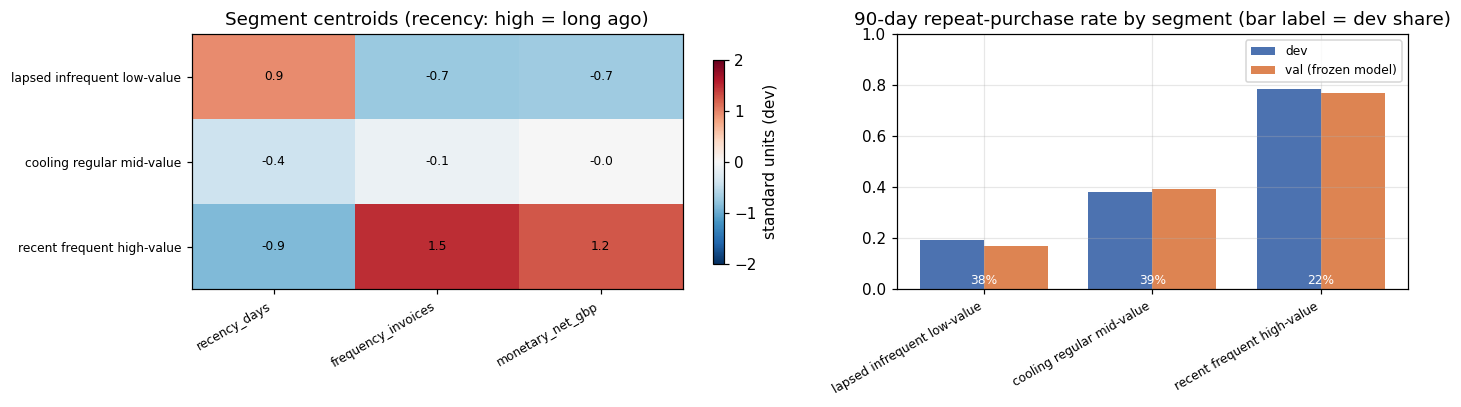

In [10]:
cent = pd.DataFrame(model.centroids, columns=model.preprocessor.features, index=[model.names[j] for j in range(model.k)])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.2, 1]})
im = ax[0].imshow(cent.to_numpy(), cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax[0].set_xticks(range(cent.shape[1]), cent.columns, rotation=30, ha="right", fontsize=8)
ax[0].set_yticks(range(cent.shape[0]), cent.index, fontsize=8); ax[0].grid(False)
for i in range(cent.shape[0]):
    for j in range(cent.shape[1]):
        ax[0].text(j, i, f"{cent.iat[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax[0], shrink=0.8, label="standard units (dev)")
ax[0].set_title("Segment centroids (recency: high = long ago)")
x = np.arange(model.k); w = 0.38
ax[1].bar(x - w / 2, prof.repeat_rate, w, label="dev", color="#4C72B0")
ax[1].bar(x + w / 2, prof.val_repeat_rate, w, label="val (frozen model)", color="#DD8452")
for i, s in enumerate(prof.share):
    ax[1].text(i, 0.02, f"{100 * s:.0f}%", ha="center", color="white", fontsize=8)
ax[1].set_xticks(x, [model.names[j] for j in range(model.k)], rotation=30, ha="right", fontsize=8)
ax[1].set(title="90-day repeat-purchase rate by segment (bar label = dev share)", ylim=(0, 1)); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "seg_profiles.png")

## 6. Stability and sensitivity
S3 is the plan's stability metric (minimum useful 0.70, stretch 0.85). Temporal stability compares the frozen dev model with the same recipe refitted on val. Sensitivities refit without the top 1% of customers and with exact duplicates kept.

In [11]:
con_keep = connect(cfg)
clean_lines(con_keep, raw, cfg, drop_duplicates=False)
dev_keep = build_snapshot(con_keep, cfg, cfg["windows"]["snapshots"]["dev"]["cutoff"])
refit_keep = fit_segment_model(dev_keep, result["chosen_set"], model.k, cfg)
dup_ari = float(adjusted_rand_score(model.predict(dev_keep), refit_keep.predict(dev_keep)))
stab = dict(result["stability"], duplicates_kept_ari=dup_ari)
pd.Series(stab)

S3_ari_p05                             0.882136
ari_median                             0.927118
minimum_useful                              0.7
meets_minimum                              True
temporal_ari_dev_model_vs_val_refit    0.787889
top_share_removed_ari                  0.865444
duplicates_kept_ari                    0.938419
dtype: object

## 7. Frozen record

In [12]:
path = save_selection(result, cfg, extra={
    "duplicates_kept_ari": dup_ari,
    "diagnostic_B_variants_dev_only": diag.to_dict(orient="records"),
    "profiles_dev": prof.reset_index().to_dict(orient="records"),
})
print("Saved", path.relative_to(cfg["_root"]).as_posix(), "and outputs/models/segmentation_frozen.json")

Saved outputs/metrics/segmentation_selection.json and outputs/models/segmentation_frozen.json


## 8. Key findings for the checkpoint

In [13]:
g = result["grids"][result["chosen_set"]].set_index("k").loc[model.k]
v = result["val_segment_score_auc"][result["chosen_set"]]
r, rc = result["rfm_rule_val_auc"], result["recency_only_val_auc"]
findings = [
    "Size rule: " + "; ".join(
        f"{n}: " + ("no eligible k" if result["chosen_k"][n] is None else f"eligible k {sorted(result['grids'][n].loc[result['grids'][n].size_ok, 'k'].tolist())}, chosen k={result['chosen_k'][n]} (ARI p05 {result['grids'][n].set_index('k').loc[result['chosen_k'][n], 'ari_p05']:.3f})")
        for n in result["grids"]
    ),
    f"Chosen: {result['chosen_set']} with k={model.k} (ARI 5th percentile {g.ari_p05:.3f}, silhouette {g.silhouette:.3f}, smallest segment {100 * g.min_segment_share:.1f}%).",
    f"S3 stability {g.ari_p05:.3f} against minimum useful {cfg['segmentation']['stability_min']} ({'meets' if g.ari_p05 >= cfg['segmentation']['stability_min'] else 'misses'} it); temporal ARI {stab['temporal_ari_dev_model_vs_val_refit']:.3f}; top-1% removed ARI {stab['top_share_removed_ari']:.3f}; duplicates kept ARI {dup_ari:.3f}.",
    f"Val window (selection only): segment score AUC {v['value']:.3f} ({v['ci_low']:.3f}-{v['ci_high']:.3f}); RFM rule {r['value']:.3f} ({r['ci_low']:.3f}-{r['ci_high']:.3f}); recency only {rc['value']:.3f} ({rc['ci_low']:.3f}-{rc['ci_high']:.3f}).",
    "Segment repeat rates on dev: " + "; ".join(f"{model.names[j]} {model.segment_rates[j]:.2f} ({100 * prof.share[j]:.0f}% of customers)" for j in range(model.k)),
]
for f in findings:
    print("-", f)

- Size rule: A_rfm_core: eligible k [3, 4, 5, 6, 7], chosen k=3 (ARI p05 0.882); B_behavioural_extended: eligible k [3], chosen k=3 (ARI p05 0.329); C_no_recency_sensitivity: no eligible k
- Chosen: A_rfm_core with k=3 (ARI 5th percentile 0.882, silhouette 0.321, smallest segment 22.3%).
- S3 stability 0.882 against minimum useful 0.7 (meets it); temporal ARI 0.788; top-1% removed ARI 0.865; duplicates kept ARI 0.938.
- Val window (selection only): segment score AUC 0.753 (0.738-0.768); RFM rule 0.752 (0.736-0.767); recency only 0.736 (0.719-0.752).
- Segment repeat rates on dev: lapsed infrequent low-value 0.19 (38% of customers); cooling regular mid-value 0.38 (39% of customers); recent frequent high-value 0.78 (22% of customers)
